In [3]:
import numpy as np
from scipy.optimize import curve_fit, least_squares
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd
from IPython.display import Latex
import scipy.signal
from scipy.signal import find_peaks

In [69]:
# Raw Data

frequency = np.array([
10,
100,
500,
1000,
2000,
5000,
10000
])

voltage = np.array([
4.0,
3.4,
1.2,
0.6,
0.52,
0.124,
0.064
])

voltage = voltage / 4.0

phase = -1 * np.array([
7.2,
36,
72,
86.4,
86.4,
90,
86.4
])


Raw Data:


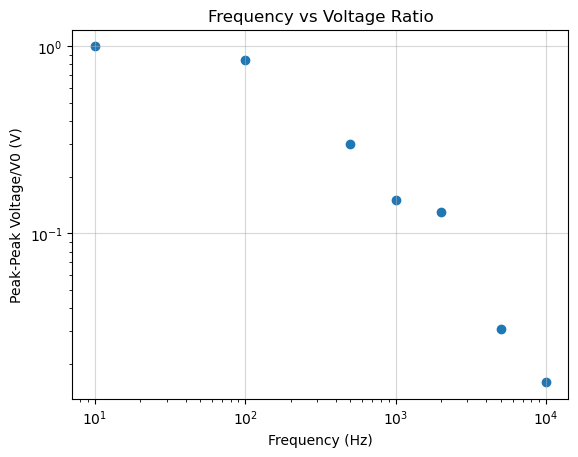

In [9]:
# Plot of Data

plt.scatter(frequency, voltage)
plt.xscale('log')
plt.yscale('log')
plt.title('Frequency vs Voltage Ratio')
plt.ylabel('Peak-Peak Voltage/V0 (V)')
plt.xlabel('Frequency (Hz)')
plt.grid(True, alpha=0.5)
print('Raw Data:')

Amplitude = 1.0010 +- 0.0207 
Time Constant = 0.0062 +- 0.0004


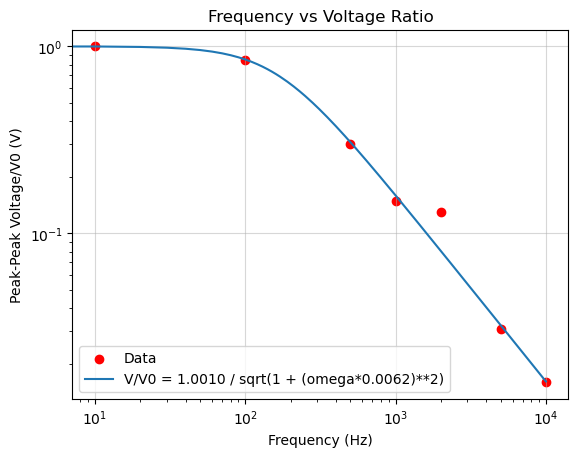

In [38]:
# Model
def model(omega, A, tau):
    return A / np.sqrt(1 + (omega*tau)**2)

param, error = curve_fit(model, frequency, voltage, p0=[1, 1], method='lm')
err = np.sqrt(np.diag(error))

# Best Fit Line
plt.scatter(frequency, voltage, c='r', label='Data')
x = np.linspace(0, 10**4, 1000)
plt.plot(x, model(x, *param), label=f'V/V0 = {param[0]:.4f} / sqrt(1 + (omega*{param[1]:.4f})**2)')
plt.xscale('log')
plt.yscale('log')
plt.title('Frequency vs Voltage Ratio')
plt.ylabel('Peak-Peak Voltage/V0 (V)')
plt.xlabel('Frequency (Hz)')
plt.grid(True, alpha=0.5)
plt.legend()

# Paramters
print(f'Amplitude = {param[0]:.4f} +- {err[0]:.4f} \nTime Constant = {param[1]:.4f} +- {err[1]:.4f}')

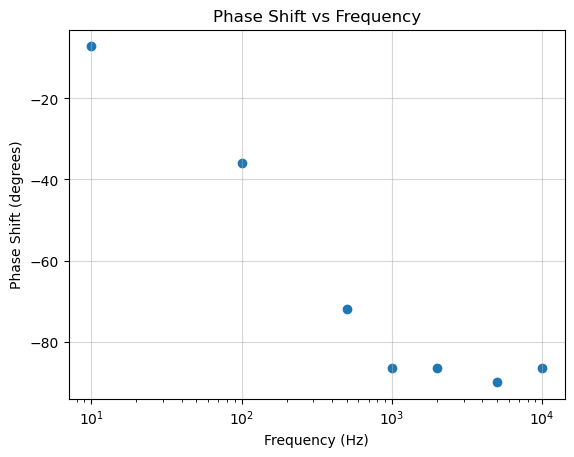

In [71]:
# Phase shift Data
plt.scatter(frequency, phase)
plt.xscale('log')
plt.title('Phase Shift vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Phase Shift (degrees)')
plt.grid(True, alpha=0.5)

Time Constant = 0.0073 +- 0.0006


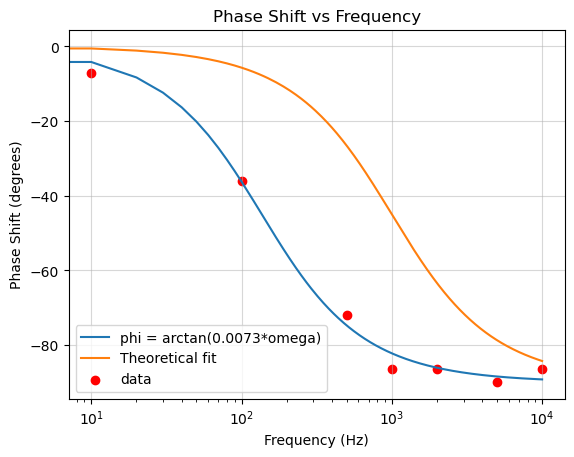

In [70]:
# Phase Model

def model(omega, tau):
    return np.degrees(np.arctan(-omega * tau))

param, error = curve_fit(model, frequency, phase, p0=[10], method='lm')
err = np.sqrt(np.diag(error))
print(f'Time Constant = {param[0]:.4f} +- {err[0]:.4f}')

x = np.linspace(0, 10**4, 1000)
plt.plot(x, model(x, *param), label=f'phi = arctan({param[0]:.4f}*omega)')
plt.plot(x, model(x, 0.001), label='Theoretical fit')
plt.scatter(frequency, phase, c='r', label='data')
plt.title('Phase Shift vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Phase Shift (degrees)')
plt.grid(True, alpha=0.5)
plt.xscale('log')
plt.legend()